# picomake - activations_gradients

In [47]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
%matplotlib inline

In [8]:
words = open("names.txt", "r").read().split()
words[:3]

# build vocabulary

stoi = {}
stoi['.'] = 0
vocab = sorted(list(set(letters for word in words for letters in word)))
for i, ch in enumerate(vocab, start = 1):
    stoi[ch] = i
stoi

{'.': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

In [9]:
# build out dataset
def build_dataset(words):
    context_size = 3
    X = []
    Y = []

    for w in words:
        context = [0]*context_size

        for i in w+'.':
            ix = stoi[i]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context [1:] + [ix]


    X = torch.tensor(X) # X stores the context of one training example in chunk of context size (stoi)
    Y = torch.tensor(Y) # Y stores the stoi value of each char in the word
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# let us create an embedding matrix where every character 
# gets a 2 dimensional embedding using the awesome pytorch indexing
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2), generator=g)
emb = C[Xtr] # torch.Size([182625, 3, 2])

In [ ]:
# neural network

# prepare out training data

W1 = torch.randn((30, 300), generator=g) * ((5/3) / math.sqrt(30)) # see below for explanation
b1 = torch.randn(300, generator=g) * 0
C = torch.randn((27,10), generator=g)
W2 = torch.randn((300, 27), generator=g) * 0.01 # we need smaller numbers to prevent exploding first loss
b2 = torch.randn(27, generator=g) * 0 # i mean why not
parameters = (C, W1, b1, W2, b2)

print(f"number of parameters = {sum(p.nelement() for p in parameters)}")

for p in parameters:
    p.requires_grad = True

# finding a good lr
lre = torch.linspace(-3, 0, 30000)
lre = 10**lre




number of parameters = 17697


In [41]:
# =================================FULL TRAINING LOOP================================#

losses = []
lrs = []
steps = []

for i in range(500000):

    # batch gradient descent

    ix = torch.randint(0, Xtr.shape[0], (64, ))

    # forward pass
    emb = C[Xtr[ix]]

    h = emb.view(-1, 30) @ W1 + b1 # -1 means any rows
    h1 = torch.tanh(h)

    logits = h1@W2 + b2

    loss = F.cross_entropy(logits, Ytr[ix])

    if i%100000==0:
        print(i, "/500000", loss)
        
    # backward pass
    # set grad = None
    for p in parameters:
        p.grad = None

    loss.backward()

    # optimise
    # lr = lre[i]
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data -= lr * p.grad

    #track
    losses.append(loss.log10().item())
    lrs.append(lr)
    steps.append(i)
    #break
    

print(loss.item())

0 /500000 tensor(3.2051, grad_fn=<NllLossBackward0>)
100000 /500000 tensor(1.8737, grad_fn=<NllLossBackward0>)
200000 /500000 tensor(2.0152, grad_fn=<NllLossBackward0>)
300000 /500000 tensor(2.1648, grad_fn=<NllLossBackward0>)
400000 /500000 tensor(1.9711, grad_fn=<NllLossBackward0>)
1.797621250152588


#### a short experiment on why such scaling factors are required for weights and biases :)

<small>

okay, so below are two figures, one a pre tanh figure and one more with a post tanh. the pre tanh figure shows a histogram of value distribution produced by the W1 @ inp + b1 layer. the layer does have some pretty large numbers on both sides of 0 which map to -1 and 1 after the activation.

    the problem is, after getting mapped near -1 and 1, the graph of tanh suggests the derivative is 0. as tanh's derivative approaches 0 
when the value is near -1 or 1, the gradients stop flowing and making an essentially a **dead neuron**. the gradients dont flow smoothly or dont flow at all resulting in slowing down the learning. a good remedy is to scale the weights to being near and around 0 so that pre activations are well distributed normally without much extreme values. with that, we can reduce the amount of -1s and 1s produced after the non linearity.
</small>

(array([1.000e+00, 1.000e+00, 0.000e+00, 4.000e+00, 5.000e+00, 8.000e+00,
        6.000e+00, 1.200e+01, 1.500e+01, 3.500e+01, 3.800e+01, 8.400e+01,
        1.100e+02, 1.260e+02, 1.920e+02, 2.380e+02, 3.610e+02, 4.650e+02,
        6.160e+02, 6.960e+02, 8.850e+02, 1.027e+03, 1.245e+03, 2.246e+03,
        4.112e+03, 1.496e+03, 1.138e+03, 9.500e+02, 7.570e+02, 5.990e+02,
        5.010e+02, 3.740e+02, 2.470e+02, 1.960e+02, 1.350e+02, 1.050e+02,
        5.700e+01, 5.300e+01, 2.500e+01, 1.600e+01, 1.100e+01, 6.000e+00,
        3.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        0.000e+00, 1.000e+00]),
 array([-13.58679581, -13.02527601, -12.46375622, -11.90223642,
        -11.34071663, -10.77919683, -10.21767704,  -9.65615725,
         -9.09463745,  -8.53311766,  -7.97159786,  -7.41007807,
         -6.84855827,  -6.28703848,  -5.72551868,  -5.16399889,
         -4.6024791 ,  -4.0409593 ,  -3.47943951,  -2.91791971,
         -2.35639992,  -1.79488012,  -1.23336033,  -0.67

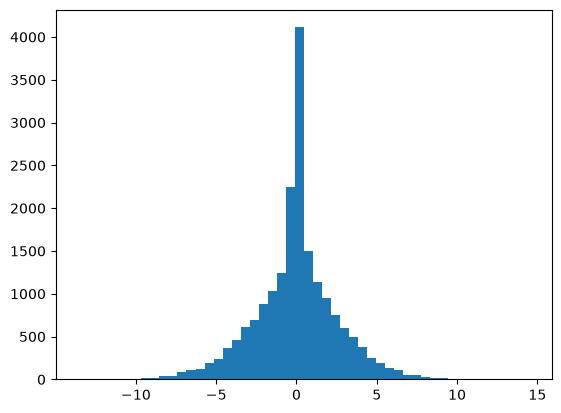

In [42]:
plt.hist(h.view(-1).tolist(), 50) #pre activation

(array([3627.,  616.,  406.,  305.,  250.,  221.,  206.,  165.,  158.,
         168.,  172.,  181.,  200.,  171.,  157.,  171.,  184.,  191.,
         204.,  149.,  204.,  244.,  305.,  362.,  582.,  631.,  394.,
         327.,  256.,  253.,  231.,  196.,  180.,  191.,  164.,  182.,
         135.,  162.,  208.,  181.,  146.,  135.,  214.,  197.,  239.,
         251.,  310.,  402.,  636., 3380.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

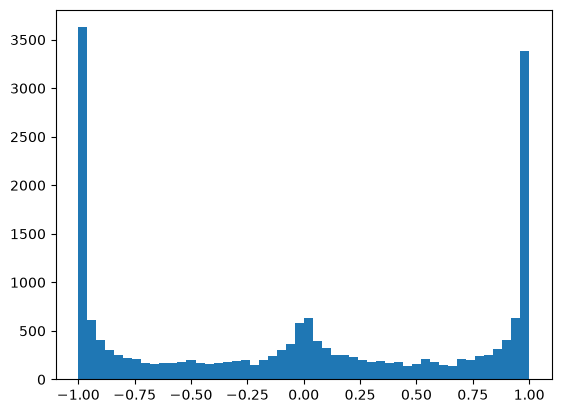

In [43]:
plt.hist(h1.view(-1).tolist(), 50) # post activation

loss vs epoch graph


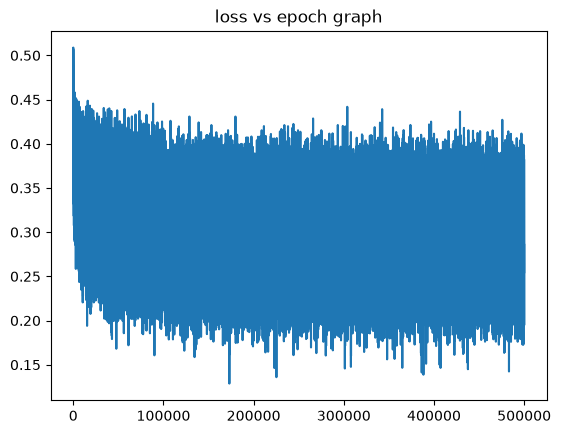

In [ ]:
plt.plot(steps, losses)
plt.title("loss vs epoch graph")

#### so how do we calculate the scaling factor for weights when dealing with multiple hidden layers?

<small>

kaiming init - [arxiv](https://arxiv.org/abs/1502.01852)

kaiming init basically gives a good guideline on approximating the scaling factor for weight inits. the formula is -> std = gain / root(fan_mode)

fan_mode is basically the number of rows in the tensor that is the first dimension. for our w1 tensor, lets calculate it. for a standard tanh, the gain is 5/3 [pytorch docs](https://docs.pytorch.org/docs/2.14/nn.init.html). so the scaling factor is roughly 5/3 * 30 which rougly comes out to be 0.3.

nowdays, many modern innovations in optimisation and normalisations actually reduce the important of such weight scaling in pre training phase.

</small>

In [45]:
# validation tests

emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
losstrain = F.cross_entropy(logits, Ytr)

emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
lossval = F.cross_entropy(logits, Ydev)

# if nearly same, our network is underfitting. scaling up the model.
print(f"training loss - {losstrain}\n validation loss - {lossval}")


training loss - 1.9917590618133545
 validation loss - 2.0943236351013184


In [50]:
((5/3) / math.sqrt(30))

0.3042903097250923